# Tarea 7. Clasificación de dígitos 0-9 con MNIST

**Materia:** Inteligencia Artificial
**Alumno:** Daniel Jimenez Duarte
**No. de control:** 23170198

En este cuaderno entrenamos una red neuronal para reconocer dígitos escritos a mano usando el dataset **MNIST**,
y guardamos el modelo ya entrenado en un archivo (`modelo_mnist.keras`). Después ese archivo se carga en un
programa aparte (`reconocer_digito.py`) para probarlo en tiempo real dibujando con el mouse.

Para ejecutarlo en Google Colab: menú **Entorno de ejecución > Ejecutar todo**. Con la CPU normal tarda menos de
un minuto.

## 1. Librerías

In [3]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Semilla fija para que los resultados se parezcan entre ejecuciones
keras.utils.set_random_seed(42)
print('Keras', keras.__version__)

Keras 3.15.1


## 2. Cargar el dataset

MNIST son imágenes de dígitos escritos a mano, en blanco y negro y de 28 × 28 píxeles. Trae 60,000 imágenes para
entrenar y 10,000 aparte para probar el modelo con datos que nunca vio.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (60000, 28, 28) (60000,)
Prueba: (10000, 28, 28) (10000,)
Valores de los pixeles: de 0 a 255


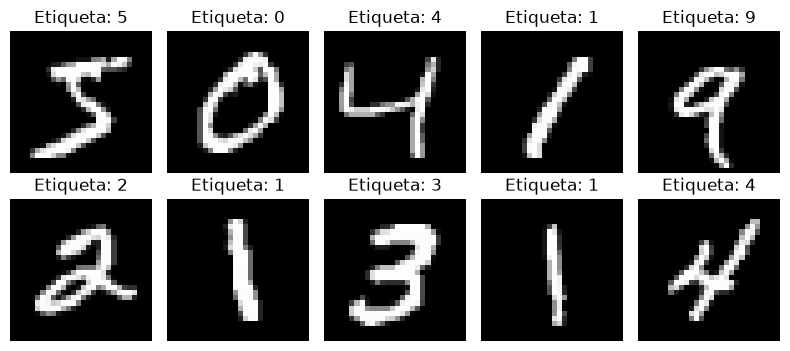

In [4]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

# Carga MNIST (viene incluido en Keras)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print('Entrenamiento:', x_train.shape, y_train.shape)
print('Prueba:', x_test.shape, y_test.shape)
print('Valores de los pixeles: de', x_train.min(), 'a', x_train.max())

# Muestra 10 ejemplos con su etiqueta
figura, ejes = plt.subplots(2, 5, figsize=(8, 3.6))
for i, eje in enumerate(ejes.ravel()):
    eje.imshow(x_train[i], cmap='gray')
    eje.set_title(f'Etiqueta: {y_train[i]}')
    eje.axis('off')
plt.tight_layout()
plt.show()

## 3. Modelo

Usamos una red neuronal densa (perceptrón multicapa):

- **Rescaling:** pasa los píxeles de 0-255 a 0-1, porque la red aprende mejor con valores chicos. Va dentro del
  modelo, así el programa que lo use después no tiene que normalizar nada.
- **Flatten:** convierte la imagen de 28 × 28 en una lista de 784 números.
- **Dense 256 y Dense 128 (ReLU):** capas ocultas que aprenden los rasgos de cada dígito.
- **Dropout 0.2:** en cada paso de entrenamiento apaga al azar el 20 % de las neuronas, para que el modelo no se
  memorice los ejemplos (sobreajuste).
- **Dense 10 (softmax):** una salida por dígito, con la probabilidad de que la imagen sea ese dígito.

In [5]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

modelo = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Rescaling(1.0 / 255),             # pixeles de 0-255 a 0-1
    layers.Flatten(),                         # imagen 28x28 a vector de 784
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),                      # evita que se memorice los datos
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),   # probabilidad de cada digito
])

modelo.summary()

E0000 00:00:1794982627.218490   33776 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento

- **Optimizador Adam:** ajusta los pesos de la red de forma automática.
- **Pérdida `sparse_categorical_crossentropy`:** mide qué tan lejos quedó la probabilidad que dio el modelo de la
  respuesta correcta. Se usa esta versión porque las etiquetas son números del 0 al 9.
- **10 épocas:** el modelo ve los 60,000 ejemplos 10 veces.
- **Lotes de 128:** actualiza los pesos cada 128 imágenes.
- **`validation_split=0.1`:** aparta el 10 % de los datos de entrenamiento para ir revisando, época por época, si el
  modelo también acierta con imágenes que no usó para aprender.

In [6]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

historial = modelo.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=2,
)

Epoch 1/10


422/422 - 2s - 5ms/step - accuracy: 0.9054 - loss: 0.3231 - val_accuracy: 0.9668 - val_loss: 0.1150
Epoch 2/10
422/422 - 1s - 3ms/step - accuracy: 0.9596 - loss: 0.1344 - val_accuracy: 0.9722 - val_loss: 0.0896
Epoch 3/10
422/422 - 1s - 3ms/step - accuracy: 0.9705 - loss: 0.0944 - val_accuracy: 0.9755 - val_loss: 0.0835
Epoch 4/10
422/422 - 1s - 3ms/step - accuracy: 0.9771 - loss: 0.0727 - val_accuracy: 0.9765 - val_loss: 0.0767
Epoch 5/10
422/422 - 1s - 3ms/step - accuracy: 0.9806 - loss: 0.0603 - val_accuracy: 0.9757 - val_loss: 0.0797
Epoch 6/10
422/422 - 1s - 3ms/step - accuracy: 0.9830 - loss: 0.0511 - val_accuracy: 0.9793 - val_loss: 0.0761
Epoch 7/10
422/422 - 1s - 3ms/step - accuracy: 0.9861 - loss: 0.0429 - val_accuracy: 0.9783 - val_loss: 0.0797
Epoch 8/10
422/422 - 1s - 3ms/step - accuracy: 0.9878 - loss: 0.0371 - val_accuracy: 0.9820 - val_loss: 0.0685
Epoch 9/10
422/422 - 1s - 3ms/step - accuracy: 0.9895 - loss: 0.0325 - val_accuracy: 0.9793 - val_loss: 0.0740
Epoch 10/10


## 5. Resultados

Las gráficas muestran cómo fue mejorando el modelo en cada época. Si la curva de validación se separa mucho de la
de entrenamiento, el modelo se está sobreajustando.

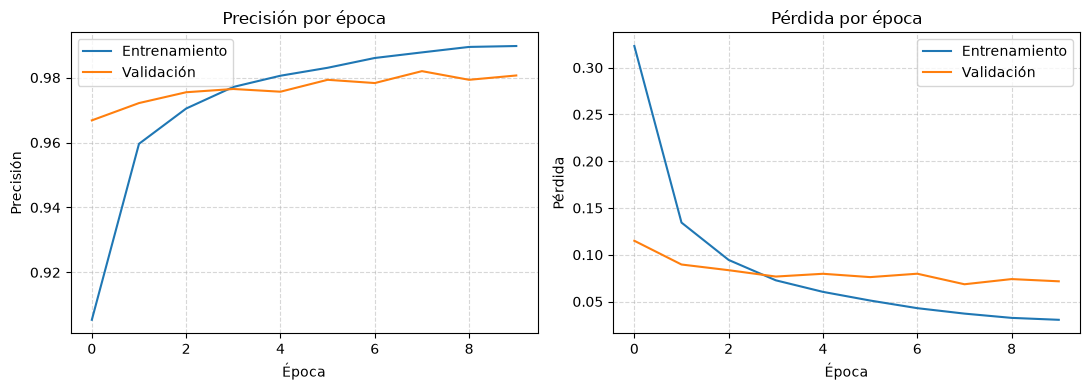

In [7]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(11, 4))

eje1.plot(historial.history['accuracy'], label='Entrenamiento')
eje1.plot(historial.history['val_accuracy'], label='Validación')
eje1.set_title('Precisión por época')
eje1.set_xlabel('Época')
eje1.set_ylabel('Precisión')
eje1.legend()
eje1.grid(True, linestyle='--', alpha=0.5)

eje2.plot(historial.history['loss'], label='Entrenamiento')
eje2.plot(historial.history['val_loss'], label='Validación')
eje2.set_title('Pérdida por época')
eje2.set_xlabel('Época')
eje2.set_ylabel('Pérdida')
eje2.legend()
eje2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [8]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

# Prueba final con las 10,000 imagenes que el modelo nunca vio
perdida, precision = modelo.evaluate(x_test, y_test, verbose=0)
print(f'Precisión en prueba: {precision:.2%}')
print(f'Pérdida en prueba:   {perdida:.4f}')

Precisión en prueba: 97.99%
Pérdida en prueba:   0.0736


### Matriz de confusión

Cada fila es el dígito real y cada columna lo que predijo el modelo. Lo ideal es que todo quede en la diagonal.
Los números fuera de la diagonal son errores.

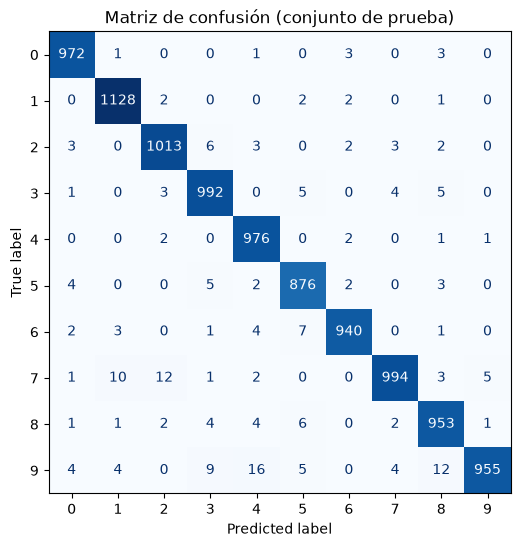

In [9]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

# Predice todo el conjunto de prueba
probabilidades = modelo.predict(x_test, verbose=0)
predicciones = np.argmax(probabilidades, axis=1)

matriz = confusion_matrix(y_test, predicciones)
figura, eje = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matriz, display_labels=range(10)).plot(ax=eje, cmap='Blues', colorbar=False)
eje.set_title('Matriz de confusión (conjunto de prueba)')
plt.show()

Imágenes mal clasificadas: 201 de 10000


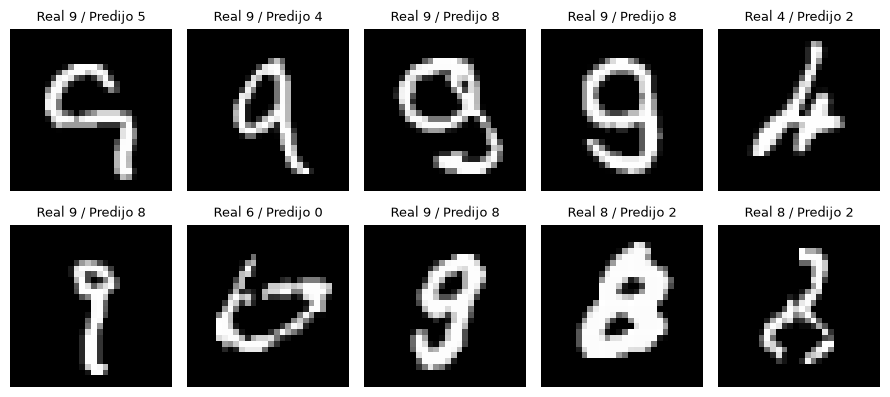

In [10]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

# Muestra algunos errores del modelo
errores = np.where(predicciones != y_test)[0]
print('Imágenes mal clasificadas:', len(errores), 'de', len(y_test))

figura, ejes = plt.subplots(2, 5, figsize=(9, 4.2))
for eje, i in zip(ejes.ravel(), errores[:10]):
    eje.imshow(x_test[i], cmap='gray')
    eje.set_title(f'Real {y_test[i]} / Predijo {predicciones[i]}', fontsize=9)
    eje.axis('off')
plt.tight_layout()
plt.show()

## 6. Guardar el modelo

El modelo se guarda en un solo archivo `.keras` que ya incluye la arquitectura y los pesos entrenados. Ese archivo
es el que carga el programa `reconocer_digito.py`. En Colab se descarga solo a la computadora.

In [11]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

modelo.save('modelo_mnist.keras')
print('Modelo guardado como modelo_mnist.keras')

# En Colab lo descarga a la computadora
try:
    from google.colab import files
    files.download('modelo_mnist.keras')
except ImportError:
    print('No estoy en Colab, el archivo quedó en la carpeta actual')

Modelo guardado como modelo_mnist.keras
No estoy en Colab, el archivo quedó en la carpeta actual


## Conclusiones

In [12]:
# Alumno: Daniel Jimenez Duarte
# No. de control: 23170198

# Resumen con los números de esta ejecución
acierto_por_digito = matriz.diagonal() / matriz.sum(axis=1)
mejor = int(np.argmax(acierto_por_digito))
peor = int(np.argmin(acierto_por_digito))
pares = [(int(matriz[r, c]), r, c) for r in range(10) for c in range(10) if r != c]
n_conf, real, pred = max(pares)

print(f'El modelo acertó el {precision:.2%} de las 10,000 imágenes de prueba.')
print(f'El dígito que mejor reconoce es el {mejor} ({acierto_por_digito[mejor]:.2%}) y el que más se le dificulta es el {peor} ({acierto_por_digito[peor]:.2%}).')
print(f'La confusión más común es tomar un {real} por un {pred} ({n_conf} veces).')
print(f'En validación llegó a {historial.history["val_accuracy"][-1]:.2%} y en entrenamiento a {historial.history["accuracy"][-1]:.2%}.')

El modelo acertó el 97.99% de las 10,000 imágenes de prueba.
El dígito que mejor reconoce es el 4 (99.39%) y el que más se le dificulta es el 9 (94.65%).
La confusión más común es tomar un 9 por un 4 (16 veces).
En validación llegó a 98.07% y en entrenamiento a 98.97%.


Con una red densa sencilla se logra una precisión alta, aunque una red convolucional (CNN) suele
reconocer mejor las imágenes porque aprovecha la forma y la posición de los trazos. Esa es la que usamos en la Tarea 8.

Lo que importa para la aplicación es que el archivo `modelo_mnist.keras` ya contiene todo lo aprendido, así que
se puede usar en cualquier programa sin volver a entrenar.